# Dataset Installation

In [1]:
import urllib.request
import zipfile
from pathlib import Path

DATA_DIR = Path("data")
ZIP_PATH = Path("ecommerce-dataset.zip")
URL = "https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset"

if DATA_DIR.exists() and any(DATA_DIR.glob("*.csv")):
    print("Dataset already installed, skipping.")
else:
    DATA_DIR.mkdir(exist_ok=True)
    print("Downloading dataset...")
    urllib.request.urlretrieve(URL, ZIP_PATH)
    print("Unzipping into data/...")
    with zipfile.ZipFile(ZIP_PATH) as zf:
        zf.extractall(DATA_DIR)
    ZIP_PATH.unlink()
    print("Done.")

Dataset already installed, skipping.


# Setup

In [2]:
import time

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import scipy.sparse as sp
from neo4j import GraphDatabase

NEO4J_URL = "neo4j://127.0.0.1:7687"
NEO4J_AUTH = ("neo4j", "pika1234")
NEO4J_DB = "retailrocket"

driver = GraphDatabase.driver(NEO4J_URL, auth=NEO4J_AUTH)


def run_query(query, database=NEO4J_DB, **params):
    """Run a Cypher query and return the result as a list of dicts."""
    with driver.session(database=database) as session:
        return [record.data() for record in session.run(query, **params)]


run_query("RETURN 1 AS ok", database="neo4j")

[{'ok': 1}]

# 1. Choosing the Time Periods (Filter)

The RetailRocket `events.csv` dataset records visitor interactions (`view`, `addtocart`, `transaction`)
with a `timestamp` in milliseconds (UTC). Two periods of **9 days** each were chosen:

| Fold | Period |
|---|---|
| Training (P1) | 03/05/2015 0:00:00 – 12/05/2015 0:00:00 |
| Testing (P2) | 03/07/2015 0:00:00 – 12/07/2015 0:00:00 |

The lower bound is inclusive and the upper bound exclusive (`start <= t < end`), so each period covers
3 May–11 May and 3 July–11 July. Both periods have the same length and the same day-of-month window,
which keeps the two folds comparable, and the two-month gap places the testing fold genuinely in the
"future" relative to the training fold. P1 starts on the first day of the dataset, whose first event is
at 03:00, so the first day of P1 is slightly shorter.

In [3]:
from pathlib import Path

DATA_DIR = Path("data")

PERIODS = {
    "P1": ("2015-05-03 00:00:00", "2015-05-12 00:00:00"),  # training fold
    "P2": ("2015-07-03 00:00:00", "2015-07-12 00:00:00"),  # testing fold
}

events = pd.read_csv(DATA_DIR / "events.csv")
events["datetime"] = pd.to_datetime(events["timestamp"], unit="ms")

print("Total events :", len(events))
print("Data range   :", events["datetime"].min(), "to", events["datetime"].max())
events.head()

Total events : 2756101
Data range   : 2015-05-03 03:00:04.384000 to 2015-09-18 02:59:47.788000


,timestamp,visitorid,event,itemid,transactionid,datetime
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106


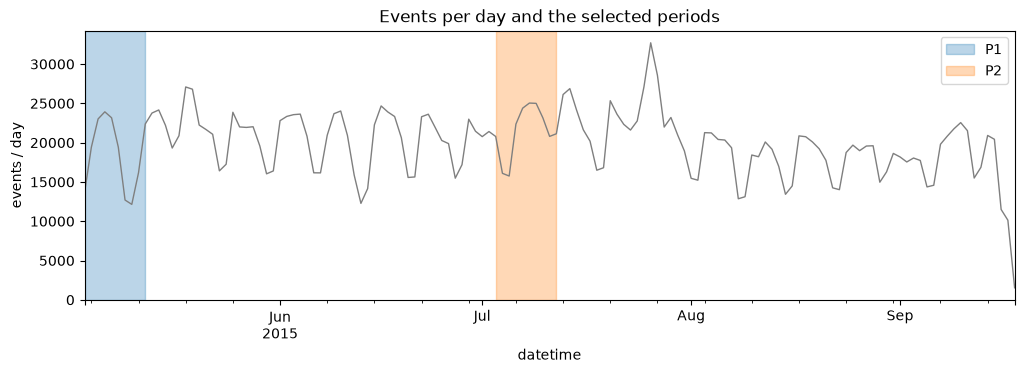

In [4]:
daily = events.set_index("datetime").resample("D").size()

fig, ax = plt.subplots(figsize=(12, 3.5))
daily.plot(ax=ax, color="tab:gray", lw=1)
for (fold, (start, end)), color in zip(PERIODS.items(), ["tab:blue", "tab:orange"]):
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=color, alpha=0.3, label=fold)
ax.set_title("Events per day and the selected periods")
ax.set_ylabel("events / day")
ax.legend()
plt.show()

# 2. Applying the Filter on Timestamp and Saving to CSV

The filter is applied to the `timestamp` column (converted to `datetime`). Both folds are combined into
a single file `data/events_filtered_P1_P2.csv` with an extra `fold` column (`P1` / `P2`).

In [5]:
def filter_period(df, start, end):
    """Keep events with start <= datetime < end."""
    mask = (df["datetime"] >= pd.Timestamp(start)) & (df["datetime"] < pd.Timestamp(end))
    return df[mask]


filtered = pd.concat(
    [filter_period(events, start, end).assign(fold=fold) for fold, (start, end) in PERIODS.items()],
    ignore_index=True,
)

FILTERED_CSV = DATA_DIR / "events_filtered_P1_P2.csv"
filtered.to_csv(FILTERED_CSV, index=False)
print("Saved:", FILTERED_CSV, filtered.shape)

summary = filtered.groupby("fold").agg(
    start=("datetime", "min"),
    end=("datetime", "max"),
    events=("event", "size"),
    users=("visitorid", "nunique"),
    items=("itemid", "nunique"),
)
summary = summary.join(filtered.pivot_table(index="fold", columns="event", values="timestamp", aggfunc="size"))
summary

Saved: data\events_filtered_P1_P2.csv (356978, 7)


,start,end,events,users,items,addtocart,transaction,view
fold,,,,,,,,
P1,2015-05-03 03:00:04.384,2015-05-11 23:59:56.995,163636,87871,54765,4178,1270,158188
P2,2015-07-03 00:00:06.417,2015-07-11 23:59:57.604,193342,106195,63326,4950,1585,186807


### Preparing the data for the graph

In [6]:
item_ids = set(filtered["itemid"])

parts = []
for name in ["item_properties_part1.csv", "item_properties_part2.csv"]:
    for chunk in pd.read_csv(DATA_DIR / name, chunksize=2_000_000):
        parts.append(chunk[(chunk["property"] == "categoryid") & chunk["itemid"].isin(item_ids)])

item_category = (
    pd.concat(parts)
    .sort_values("timestamp")
    .drop_duplicates("itemid", keep="last")[["itemid", "value"]]
    .rename(columns={"value": "categoryid"})
    .astype({"categoryid": int})
)

category_tree = pd.read_csv(DATA_DIR / "category_tree.csv")
used = category_tree[category_tree["categoryid"].isin(item_category["categoryid"])]
categories = pd.DataFrame({
    "categoryid": [int(c) for c in used["categoryid"]],
    "parentid": [None if pd.isna(p) else int(p) for p in used["parentid"]],
}, dtype=object)

print("Items with a category :", len(item_category), "of", len(item_ids))
print("Categories used       :", len(categories))

Items with a category : 77054 of 91785
Categories used       : 993


### Loading into Neo4j

Graph schema (database `retailrocket`):

```
(:User {id})-[:VIEWED | ADDED_TO_CART | PURCHASED {timestamp, fold}]->(:Item {id})-[:IN_CATEGORY]->(:Category {id, parentid})
```

Every event becomes one relationship, so the time and fold information is kept on the relationship.
Data is sent in batches of 10,000 rows using `UNWIND`.

In [7]:
EVENT_REL = {"view": "VIEWED", "addtocart": "ADDED_TO_CART", "transaction": "PURCHASED"}

run_query(f"CREATE OR REPLACE DATABASE {NEO4J_DB} WAIT", database="system")
for label in ["User", "Item", "Category"]:
    run_query(f"CREATE CONSTRAINT {label.lower()}_id IF NOT EXISTS FOR (n:{label}) REQUIRE n.id IS UNIQUE")


def load_batches(query, df, batch_size=10_000):
    rows = df.to_dict("records")
    for i in range(0, len(rows), batch_size):
        run_query(query, rows=rows[i:i + batch_size])


start = time.time()
load_batches("UNWIND $rows AS r CREATE (:User {id: r.id})",
             pd.DataFrame({"id": filtered["visitorid"].unique()}))
load_batches("UNWIND $rows AS r CREATE (:Item {id: r.id})",
             pd.DataFrame({"id": filtered["itemid"].unique()}))
load_batches("UNWIND $rows AS r CREATE (:Category {id: r.categoryid, parentid: r.parentid})",
             categories)
load_batches("""
    UNWIND $rows AS r
    MATCH (i:Item {id: r.itemid}), (c:Category {id: r.categoryid})
    CREATE (i)-[:IN_CATEGORY]->(c)
""", item_category)

for event, rel in EVENT_REL.items():
    subset = filtered.loc[filtered["event"] == event, ["visitorid", "itemid", "timestamp", "fold"]]
    load_batches(f"""
        UNWIND $rows AS r
        MATCH (u:User {{id: r.visitorid}}), (i:Item {{id: r.itemid}})
        CREATE (u)-[:{rel} {{timestamp: r.timestamp, fold: r.fold}}]->(i)
    """, subset)

print(f"Load finished in {time.time() - start:.1f} seconds")

Load finished in 72.0 seconds


# 3. Subgraph Composition

The subgraph composition is queried directly from Neo4j through the Python API (`session.run`).

In [8]:
node_composition = pd.DataFrame(run_query("""
    MATCH (n)
    RETURN labels(n)[0] AS node_type, count(*) AS count
    ORDER BY count DESC
"""))
node_composition

,node_type,count
0,User,193000
1,Item,91785
2,Category,993


In [9]:
rel_composition = pd.DataFrame(run_query("""
    MATCH ()-[r]->()
    RETURN type(r) AS relationship_type, r.fold AS fold, count(*) AS count
    ORDER BY relationship_type, fold
"""))
rel_composition.pivot_table(index="relationship_type", columns="fold", values="count", aggfunc="sum", dropna=False)

fold,P1,P2,NaN
relationship_type,,,
ADDED_TO_CART,4178.0,4950.0,NaN
IN_CATEGORY,NaN,NaN,77054.0
PURCHASED,1270.0,1585.0,NaN
VIEWED,158188.0,186807.0,NaN


In [10]:
fold_composition = pd.DataFrame(run_query("""
    MATCH (u:User)-[r]->(i:Item)
    RETURN r.fold AS fold,
           count(DISTINCT u) AS users,
           count(DISTINCT i) AS items,
           count(r) AS interactions
    ORDER BY fold
"""))
fold_composition

,fold,users,items,interactions
0,P1,87871,54765,163636
1,P2,106195,63326,193342


In [11]:
top_categories = pd.DataFrame(run_query("""
    MATCH (i:Item)-[:IN_CATEGORY]->(c:Category)
    RETURN c.id AS categoryid, count(i) AS items
    ORDER BY items DESC
    LIMIT 10
"""))
top_categories

,categoryid,items
0,342,1494
1,1483,1422
2,1051,1361
3,491,1143
4,769,1042
5,959,983
6,196,867
7,242,842
8,1221,754
9,646,643


### Explanation of the Cypher queries used

1. **Node types and counts**
   ```cypher
   MATCH (n) RETURN labels(n)[0] AS node_type, count(*) AS count ORDER BY count DESC
   ```
   `MATCH (n)` matches every node. `labels(n)` returns the list of labels of a node (each node here has
   exactly one label, so element `[0]` is taken). `count(*)` is an aggregation, so Cypher implicitly
   groups by the non-aggregated column (`node_type`), similar to `GROUP BY` in SQL.

2. **Relationship types per fold**
   ```cypher
   MATCH ()-[r]->() RETURN type(r) AS relationship_type, r.fold AS fold, count(*) AS count
   ```
   The pattern `()-[r]->()` matches every directed relationship. `type(r)` gives the relationship type
   name and `r.fold` reads the fold property; the rows are then counted per combination of the two.

3. **Users, items and interactions per fold**
   ```cypher
   MATCH (u:User)-[r]->(i:Item) RETURN r.fold, count(DISTINCT u), count(DISTINCT i), count(r)
   ```
   The pattern is restricted to `User` → `Item`. `count(DISTINCT ...)` is needed because a single
   user/item can appear in many relationships; without `DISTINCT` it would count rows (interactions).

4. **Categories with the most items**: the pattern `(:Item)-[:IN_CATEGORY]->(:Category)` is counted per
   category, sorted descending with `ORDER BY ... DESC` and limited with `LIMIT 10`.

# 4. Vector Space Model (VSM) – User Nodes

Interactions from the training fold (P1) are queried from Neo4j and arranged into a user × item matrix
`W`. The weight of each interaction type reflects the strength of interest:

| Relationship | Weight |
|---|---|
| VIEWED | 1 |
| ADDED_TO_CART | 3 |
| PURCHASED | 5 |

`W[u, i]` is the sum of the weights of all interactions of user `u` with item `i`. In the user VSM,
**each user is one vector (a row of `W`) in a space whose dimension is the number of items**. The binary
matrix `B = (W > 0)` is used for the bipartite projection: `B·Bᵀ` produces the user–user graph, where two
users are connected if they interacted with the same item (edge weight = number of shared items).

In [12]:
EVENT_WEIGHT = {"VIEWED": 1, "ADDED_TO_CART": 3, "PURCHASED": 5}

interactions = pd.DataFrame(run_query("""
    MATCH (u:User)-[r]->(i:Item)
    WHERE r.fold = $fold
    RETURN u.id AS user, i.id AS item, type(r) AS event, count(*) AS n
""", fold="P1"))

interactions["w"] = interactions["event"].map(EVENT_WEIGHT) * interactions["n"]
user_item = interactions.groupby(["user", "item"], as_index=False)["w"].sum()

users = pd.Index(user_item["user"].unique(), name="user")
items = pd.Index(user_item["item"].unique(), name="item")

W = sp.csr_matrix(
    (user_item["w"].astype(np.float32), (users.get_indexer(user_item["user"]), items.get_indexer(user_item["item"]))),
    shape=(len(users), len(items)),
)
B = (W > 0).astype(np.float32)
print("User x item matrix:", W.shape, "| nnz:", W.nnz)

User x item matrix: (87871, 54765) | nnz: 128864


In [13]:
def describe_vsm(M, entity, dim_entity):
    """VSM characteristics: each row of M is one vector."""
    M = M.tocsr()
    nnz_per_vec = np.diff(M.indptr)
    n_vec, dim = M.shape
    stats = {
        "number of vectors": f"{n_vec:,} {entity}s",
        "vector dimension": f"{dim:,} ({dim_entity})",
        "matrix shape": M.shape,
        "non-zero elements": f"{M.nnz:,}",
        "sparsity": f"{1 - M.nnz / (n_vec * dim):.6%}",
        "mean non-zeros per vector": round(nnz_per_vec.mean(), 3),
        "median non-zeros per vector": int(np.median(nnz_per_vec)),
        "max non-zeros per vector": int(nnz_per_vec.max()),
        "vectors with only 1 non-zero": f"{(nnz_per_vec == 1).mean():.2%}",
        "sparse memory (CSR)": f"{(M.data.nbytes + M.indices.nbytes + M.indptr.nbytes) / 1e6:.1f} MB",
        "memory if dense (float32)": f"{n_vec * dim * 4 / 1e9:.1f} GB",
    }
    return pd.Series(stats, name=f"{entity} VSM")


def project(B):
    """Bipartite projection onto the row side: (B @ B.T) without the diagonal, weight = shared neighbours."""
    P = (B @ B.T).tocsr()
    P.setdiag(0)
    P.eliminate_zeros()
    return P


def describe_projection(P, entity, elapsed):
    G = nx.from_scipy_sparse_array(P)
    n = G.number_of_nodes()
    components = list(nx.connected_components(G))
    largest = max(components, key=len)
    stats = {
        "nodes": f"{n:,}",
        "edges": f"{G.number_of_edges():,}",
        "density": f"{nx.density(G):.6f}",
        "mean degree": round(2 * G.number_of_edges() / n, 2),
        "max degree": max(d for _, d in G.degree()),
        "isolated nodes": f"{nx.number_of_isolates(G):,} ({nx.number_of_isolates(G) / n:.1%})",
        "connected components": f"{len(components):,}",
        "largest component": f"{len(largest):,} nodes ({len(largest) / n:.1%})",
        "avg clustering (approx.)": round(nx.approximation.average_clustering(G, trials=5000, seed=42), 4),
        "projection time": f"{elapsed * 1000:.0f} ms",
    }
    return G, pd.Series(stats, name=f"{entity} projection")


def plot_projection(G, title, color, n_sample=150, seed=42):
    """Degree distribution (log-log) + a BFS sample subgraph from a random node in the largest component."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

    degrees = np.array([d for _, d in G.degree()])
    values, counts = np.unique(degrees[degrees > 0], return_counts=True)
    ax1.loglog(values, counts, "o", ms=3, color=color)
    ax1.set_xlabel("degree")
    ax1.set_ylabel("number of nodes")
    ax1.set_title(f"Degree distribution – {title}")

    rng = np.random.default_rng(seed)
    largest = list(max(nx.connected_components(G), key=len))
    root = largest[rng.integers(len(largest))]
    sample = [root] + [v for _, v in nx.bfs_edges(G, root)][: n_sample - 1]
    H = G.subgraph(sample)
    pos = nx.spring_layout(H, seed=seed)
    nx.draw_networkx_edges(H, pos, ax=ax2, alpha=0.2)
    nx.draw_networkx_nodes(H, pos, ax=ax2, node_size=[10 + 3 * H.degree(v) for v in H], node_color=color)
    ax2.set_title(f"Sample subgraph of the {title} ({H.number_of_nodes()} nodes, {H.number_of_edges()} edges)")
    ax2.axis("off")
    plt.tight_layout()
    plt.show()

In [14]:
user_vsm = describe_vsm(W, "user", "number of items")
user_vsm.to_frame()

,user VSM
number of vectors,"87,871 users"
vector dimension,"54,765 (number of items)"
matrix shape,"(87871, 54765)"
non-zero elements,"128,864"
sparsity,99.997322%
mean non-zeros per vector,1.467
median non-zeros per vector,1
max non-zeros per vector,397
vectors with only 1 non-zero,81.24%
sparse memory (CSR),1.4 MB


In [15]:
# a few example user vectors (non-zero elements only)
for idx in [0, 1, 2]:
    row = W.getrow(idx)
    print(f"user {users[idx]}:", dict(zip(items[row.indices], row.data)))

user 12: {70225: np.float32(1.0)}
user 45: {451993: np.float32(1.0)}
user 55: {399556: np.float32(2.0)}


In [16]:
start = time.time()
P_user = project(B)
user_elapsed = time.time() - start

G_user, user_proj = describe_projection(P_user, "user–user", user_elapsed)
user_proj.to_frame()

,user–user projection
nodes,"87,871"
edges,"483,118"
density,0.000125
mean degree,11.0
max degree,3034
isolated nodes,"22,396 (25.5%)"
connected components,"29,735"
largest component,"42,325 nodes (48.2%)"
avg clustering (approx.),0.5334
projection time,18 ms


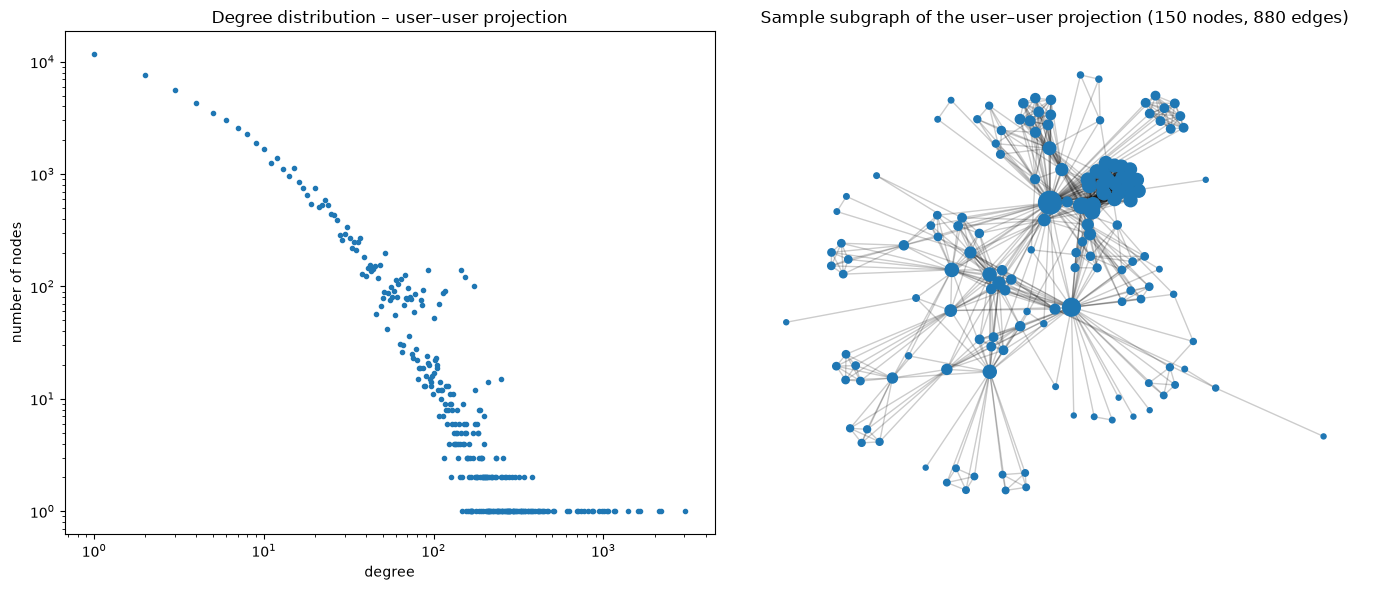

In [17]:
plot_projection(G_user, "user–user projection", "tab:blue")

### User VSM characteristics

- **Dimension & shape**: 87,871 user vectors, each of dimension **54,765** (the number of items in P1),
  so the matrix is `(87871, 54765)`.
- **Extremely sparse**: only 128,864 non-zero elements → sparsity of **99.997%**. Stored as CSR it takes
  ~1.4 MB, whereas a dense version would need ~19.2 GB. A sparse representation is essential.
- **Very little information per vector**: on average 1.47 items per user, median **1**, and **81%** of
  users interacted with only one item. Such vectors can hardly be compared meaningfully: two users who
  both viewed the same single item automatically get cosine = 1.
- **User–user projection graph**: 87,871 nodes, 483,118 edges, density 0.000125, mean degree 11.0.
  25.5% of users are isolated and the largest component covers 48.2% of the nodes.
- **Heavy-tailed degree distribution** (a straight line on the log-log plot), max degree 3,034. The
  high clustering (0.53) does not reflect real communities; it happens because every popular item forms
  a *clique*: an item viewed by k users directly produces k(k-1)/2 edges between those users.

# 5. Vector Space Model (VSM) – Item Nodes

The item VSM is the transpose of the user VSM: **each item is one vector (a row of `Wᵀ`) in a space whose
dimension is the number of users**. The projection `Bᵀ·B` produces the item–item graph, where two items are
connected if they were interacted with by the same user (edge weight = number of shared users,
*co-occurrence*).

In [18]:
W_item = W.T.tocsr()
B_item = B.T.tocsr()

item_vsm = describe_vsm(W_item, "item", "number of users")
item_vsm.to_frame()

,item VSM
number of vectors,"54,765 items"
vector dimension,"87,871 (number of users)"
matrix shape,"(54765, 87871)"
non-zero elements,"128,864"
sparsity,99.997322%
mean non-zeros per vector,2.353
median non-zeros per vector,1
max non-zeros per vector,173
vectors with only 1 non-zero,60.80%
sparse memory (CSR),1.2 MB


In [19]:
for idx in [0, 1, 2]:
    row = W_item.getrow(idx)
    print(f"item {items[idx]}:", dict(zip(users[row.indices], row.data)))

item 70225: {12: np.float32(1.0), 1109568: np.float32(1.0)}
item 451993: {45: np.float32(1.0)}
item 399556: {55: np.float32(2.0), 255607: np.float32(1.0), 668435: np.float32(1.0), 821739: np.float32(1.0), 1083943: np.float32(1.0), 1367604: np.float32(1.0)}


In [20]:
start = time.time()
P_item = project(B_item)
item_elapsed = time.time() - start

G_item, item_proj = describe_projection(P_item, "item–item", item_elapsed)
item_proj.to_frame()

,item–item projection
nodes,"54,765"
edges,"473,336"
density,0.000316
mean degree,17.29
max degree,1747
isolated nodes,"26,983 (49.3%)"
connected components,"29,735"
largest component,"20,709 nodes (37.8%)"
avg clustering (approx.),0.3014
projection time,12 ms


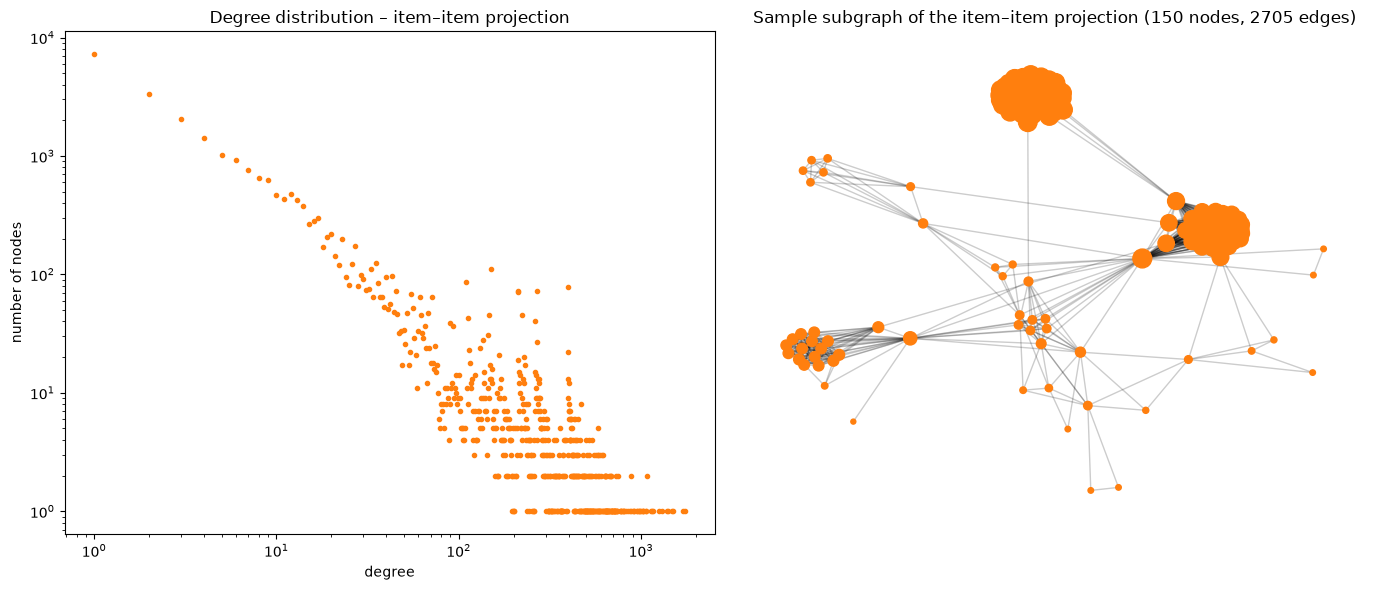

In [21]:
plot_projection(G_item, "item–item projection", "tab:orange")

### Item VSM characteristics

- **Dimension & shape**: 54,765 item vectors, each of dimension **87,871** (the number of users in P1),
  matrix `(54765, 87871)`. It is the transpose of the user VSM, with the same number of non-zeros and
  the same sparsity (99.997%).
- **More informative vectors**: on average 2.35 users per item (vs 1.47 items per user), and the share
  of vectors with a single non-zero drops to **61%** (vs 81% for users).
- **Item–item projection graph**: 54,765 nodes, 473,336 edges. It has almost the same number of edges
  as the user projection but 38% fewer nodes, so its **density is 2.5× higher** (0.000316) and the mean
  degree is 17.3.
- 49.3% of items are isolated (items viewed only by "one-off" users), and the largest component covers
  37.8%. The number of connected components is exactly the same as in the user projection (29,735),
  because both projections come from the same bipartite graph.
- Clustering is lower (0.30), and the sample subgraph shows several clearly separated item clusters:
  groups of items that are frequently viewed together.

# 6. Comparing the User vs Item Projection

Besides the structural metrics, **stability across folds** is also checked: how many P1 users/items
appear again in P2. A projection is only useful for the testing fold if its nodes show up again.

In [22]:
comparison = pd.concat(
    [pd.concat([user_vsm, user_proj]), pd.concat([item_vsm, item_proj])],
    axis=1,
    keys=["User", "Item"],
)
comparison

,User,Item
number of vectors,"87,871 users","54,765 items"
vector dimension,"54,765 (number of items)","87,871 (number of users)"
matrix shape,"(87871, 54765)","(54765, 87871)"
non-zero elements,"128,864","128,864"
sparsity,99.997322%,99.997322%
mean non-zeros per vector,1.467,2.353
median non-zeros per vector,1,1
max non-zeros per vector,397,173
vectors with only 1 non-zero,81.24%,60.80%
sparse memory (CSR),1.4 MB,1.2 MB


In [23]:
overlap = pd.DataFrame(run_query("""
    MATCH (n)-[r]-()
    WHERE n:User OR n:Item
    WITH labels(n)[0] AS node_type, n, collect(DISTINCT r.fold) AS folds
    RETURN node_type,
           count(CASE WHEN 'P1' IN folds THEN 1 END) AS in_P1,
           count(CASE WHEN 'P1' IN folds AND 'P2' IN folds THEN 1 END) AS in_P1_and_P2
    ORDER BY node_type
"""))
overlap["share_seen_again_in_P2"] = (overlap["in_P1_and_P2"] / overlap["in_P1"]).map("{:.1%}".format)
overlap

,node_type,in_P1,in_P1_and_P2,share_seen_again_in_P2
0,Item,54765,26306,48.0%
1,User,87871,1066,1.2%


### Which projection is better?

**The item projection is better**, in terms of both effectiveness and efficiency:

| Aspect | User | Item | Better |
|---|---|---|---|
| Number of nodes (size of the n×n similarity matrix) | 87,871 | 54,765 | Item |
| Projection graph density | 0.000125 | 0.000316 | Item |
| Mean degree | 11.0 | 17.3 | Item |
| Vectors with only 1 non-zero | 81% | 61% | Item |
| Seen again in the testing fold P2 | **1.2%** | **48.0%** | Item |
| Projection time | tens of ms | tens of ms | ≈ equal (see table above) |

1. **Effectiveness**: item vectors have more non-zeros on average, so similarity between items is
   backed by more evidence. In contrast, most users have only a single interaction, so user similarity
   is dominated by coincidence (a score of 1.0 from one shared item).
2. **Generalisation to the testing fold**: the deciding argument. Only **1,066 of 87,871 users (1.2%)** in
   P1 appear again in P2, while **48.0% of items** do. User–user similarity from P1 is almost useless in
   P2 because the users are different, whereas item–item similarity still applies.
3. **Efficiency**: the item graph has fewer nodes with a comparable number of edges, so the potential
   n² similarity matrix is smaller (3.0 billion vs 7.7 billion pairs). Items are also far more stable over
   time, so the projection needs to be recomputed less often.

Therefore the similarity computation in question 7 is done on the **item–item projection**.

# 7. Similarity on the Item Projection Graph

Similarity is computed for every edge of the item–item projection (item pairs that share at least one
user), using three measures:

- **Cosine similarity** between the weighted item VSM vectors:
  $\cos(a,b) = \frac{w_a \cdot w_b}{\lVert w_a \rVert\,\lVert w_b \rVert}$, computed for all pairs at once
  with the sparse matrix product `W_item · W_itemᵀ`.
- **Jaccard (co-occurrence)** between the sets of users: $J(a,b) = \frac{|U_a \cap U_b|}{|U_a \cup U_b|}$.
- **Jaccard coefficient on the projection graph** (`nx.jaccard_coefficient`): the similarity of the
  neighbour sets of two items in the item–item graph.

Pairs with only 1 shared user easily score 1.0 by chance, so the ranking uses a *minimum support* of 3
shared users.

In [24]:
norms = np.sqrt(W_item.multiply(W_item).sum(axis=1)).A1
dot = sp.triu(W_item @ W_item.T, k=1).tocoo()
a, b = dot.row, dot.col

shared = np.asarray(P_item[a, b]).ravel()
n_users = np.diff(B_item.indptr)

similarity = pd.DataFrame({
    "item_a": items[a],
    "item_b": items[b],
    "shared_users": shared.astype(int),
    "cosine": dot.data / (norms[a] * norms[b]),
    "jaccard_users": shared / (n_users[a] + n_users[b] - shared),
})

# store cosine as an edge attribute on the projection graph
nx.set_edge_attributes(G_item, {(int(i), int(j)): c for i, j, c in zip(a, b, similarity["cosine"])}, "cosine")

print("Item pairs (projection edges):", f"{len(similarity):,}")
similarity.describe()[["shared_users", "cosine", "jaccard_users"]]

Item pairs (projection edges): 473,336


,shared_users,cosine,jaccard_users
count,473336.000000,473336.000000,473336.000000
mean,1.036629,0.270412,0.184499
std,0.257622,0.291072,0.229285
min,1.000000,0.000547,0.003891
25%,1.000000,0.050833,0.052632
50%,1.000000,0.144338,0.100000
75%,1.000000,0.408248,0.200000
max,19.000000,1.000000,1.000000


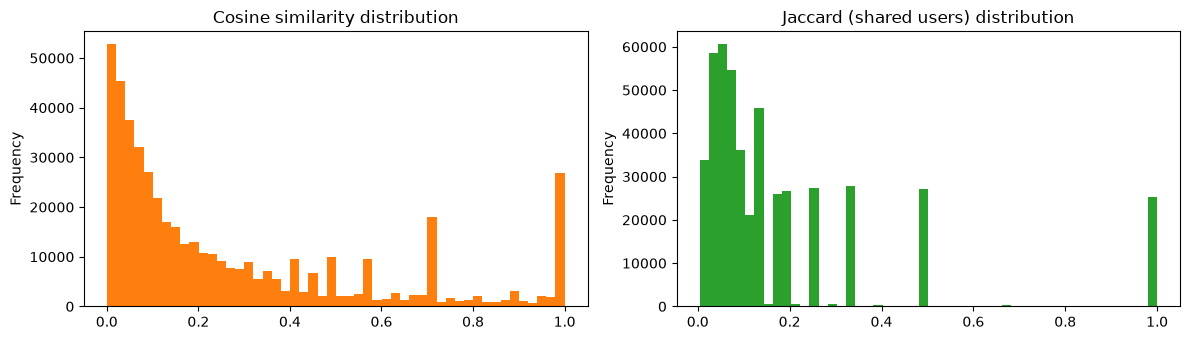

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
similarity["cosine"].plot.hist(bins=50, ax=axes[0], color="tab:orange", title="Cosine similarity distribution")
similarity["jaccard_users"].plot.hist(bins=50, ax=axes[1], color="tab:green", title="Jaccard (shared users) distribution")
plt.tight_layout()
plt.show()

In [26]:
MIN_SUPPORT = 3

top_pairs = (
    similarity[similarity["shared_users"] >= MIN_SUPPORT]
    .sort_values(["cosine", "shared_users"], ascending=False)
    .head(10)
    .reset_index(drop=True)
)

# neighbour Jaccard coefficient on the projection graph for the top pairs
index_of = {item: k for k, item in enumerate(items)}
pairs = [(index_of[x], index_of[y]) for x, y in zip(top_pairs["item_a"], top_pairs["item_b"])]
top_pairs["jaccard_graph"] = [score for _, _, score in nx.jaccard_coefficient(G_item, pairs)]
top_pairs

,item_a,item_b,shared_users,cosine,jaccard_users,jaccard_graph
0,363058,397952,4,1.000000,1.000000,0.987805
1,273940,309628,3,1.000000,1.000000,0.866667
2,106110,154405,3,0.996493,0.600000,0.964286
3,94119,222696,3,0.995274,1.000000,0.989362
4,209688,188233,4,0.993184,0.666667,0.784783
5,124093,106110,3,0.992236,0.500000,0.947368
6,80014,404977,3,0.985844,1.000000,0.980198
7,121595,417025,3,0.978451,0.750000,0.931034
8,136182,246825,6,0.975222,0.428571,0.637283
9,449391,78268,4,0.969599,0.235294,0.205448


In [27]:
def similar_items(item_id, k=5):
    """Top-k most similar items (cosine) among the item's neighbours in the projection graph."""
    node = index_of[item_id]
    neighbors = sorted(G_item[node].items(), key=lambda kv: kv[1]["cosine"], reverse=True)[:k]
    return pd.DataFrame(
        [(items[v], attr["cosine"], int(attr["weight"])) for v, attr in neighbors],
        columns=["item", "cosine", "shared_users"],
    )


# example: the item with the most users in P1
popular_item = items[n_users.argmax()]
print("Most popular item in P1:", popular_item, "| users:", n_users.max())
similar_items(popular_item)

Most popular item in P1: 369447 | users: 173


,item,cosine,shared_users
0,356129,0.560635,17
1,288939,0.444277,1
2,224582,0.444277,1
3,79579,0.444277,1
4,43557,0.441307,2


### Interpretation

- There are 473,336 item pairs connected in the projection graph. Most of them are backed by only
  **1 shared user** (mean 1.04, third quartile = 1), so high cosine/Jaccard values on those pairs are not
  yet trustworthy. This is why a *minimum support* of 3 is used.
- The top pairs have cosine 0.97–1.0 with 3–6 shared users. For most pairs the three measures agree
  (e.g. 363058–397952: cosine 1.0, user Jaccard 1.0, graph Jaccard 0.99), meaning both items were viewed
  by the same users *and* have the same neighbouring items.
- The three measures do not always agree. The pair 449391–78268 has cosine 0.97 but a user Jaccard of
  only 0.24 and a graph Jaccard of 0.21: the users they share weight both items in a similar way, but
  each item also has many users and neighbouring items the other does not.
- For the most popular item (369447, 173 users), the most similar item is 356129 with 17 shared users
  (cosine 0.56). The next three neighbours share only 1 user yet still score 0.44, so for recommendations
  cosine should be combined with *support* (the number of shared users).
- These similarities can be validated on the testing fold P2 by checking whether item pairs that are
  similar in P1 are also viewed together by users in P2.

## 7(a). Cypher Query: Top 5 Most Similar Records

**Reference record**: the most popular item in the training fold P1 (the item with the most users,
found above as `popular_item`). The weighted cosine similarity is computed entirely in Cypher, using the
same weights as the VSM (VIEWED = 1, ADDED_TO_CART = 3, PURCHASED = 5):

```cypher
// 1. vector of the reference item: weight per user
MATCH (ua:User)-[ra]->(a:Item {id: $ref})
WHERE ra.fold = 'P1'
WITH a, ua, sum(CASE type(ra) WHEN 'VIEWED' THEN 1.0 WHEN 'ADDED_TO_CART' THEN 3.0 ELSE 5.0 END) AS wa
WITH a, collect({user: ua, w: wa}) AS vec_a, sqrt(sum(wa * wa)) AS norm_a

// 2. dot product with every item b that shares a user with a
UNWIND vec_a AS x
WITH a, norm_a, x.user AS u, x.w AS wa
MATCH (u)-[rb]->(b:Item)
WHERE rb.fold = 'P1' AND b <> a
WITH a, norm_a, b, u, wa, sum(CASE type(rb) WHEN 'VIEWED' THEN 1.0 WHEN 'ADDED_TO_CART' THEN 3.0 ELSE 5.0 END) AS wb
WITH a, norm_a, b, sum(wa * wb) AS dot, count(u) AS shared_users
WHERE shared_users >= $min_support

// 3. norm of every candidate item b
MATCH (ub:User)-[rn]->(b)
WHERE rn.fold = 'P1'
WITH a, norm_a, b, dot, shared_users, ub,
     sum(CASE type(rn) WHEN 'VIEWED' THEN 1.0 WHEN 'ADDED_TO_CART' THEN 3.0 ELSE 5.0 END) AS w
WITH a, b, dot, shared_users, norm_a, sqrt(sum(w * w)) AS norm_b

// 4. cosine = dot / (|a| |b|), keep the 5 highest
RETURN a.id AS reference_item, b.id AS similar_item, shared_users,
       dot / (norm_a * norm_b) AS cosine
ORDER BY cosine DESC, shared_users DESC
LIMIT 5
```

How it works:
1. All P1 interactions with the reference item are summed per user into a weight `wa`. `collect()` stores
   that vector as a list and `sqrt(sum(wa * wa))` gives its norm ‖a‖.
2. `UNWIND` expands the vector again, and for every user it finds the other items `b` they interacted
   with. Summing `wa * wb` per `b` gives the dot product. `count(u)` gives the number of shared users,
   filtered with `$min_support` (2) so that pairs backed by a single user don't dominate the ranking.
3. For each candidate `b`, all its P1 interactions are summed per user to compute its norm ‖b‖.
4. `dot / (norm_a * norm_b)` is the cosine. `ORDER BY ... DESC LIMIT 5` keeps the five most similar items.

In [28]:
WEIGHT_CASE = "CASE type({r}) WHEN 'VIEWED' THEN 1.0 WHEN 'ADDED_TO_CART' THEN 3.0 ELSE 5.0 END"

TOP5_SIMILAR_CYPHER = f"""
MATCH (ua:User)-[ra]->(a:Item {{id: $ref}})
WHERE ra.fold = 'P1'
WITH a, ua, sum({WEIGHT_CASE.format(r="ra")}) AS wa
WITH a, collect({{user: ua, w: wa}}) AS vec_a, sqrt(sum(wa * wa)) AS norm_a

UNWIND vec_a AS x
WITH a, norm_a, x.user AS u, x.w AS wa
MATCH (u)-[rb]->(b:Item)
WHERE rb.fold = 'P1' AND b <> a
WITH a, norm_a, b, u, wa, sum({WEIGHT_CASE.format(r="rb")}) AS wb
WITH a, norm_a, b, sum(wa * wb) AS dot, count(u) AS shared_users
WHERE shared_users >= $min_support

MATCH (ub:User)-[rn]->(b)
WHERE rn.fold = 'P1'
WITH a, norm_a, b, dot, shared_users, ub, sum({WEIGHT_CASE.format(r="rn")}) AS w
WITH a, b, dot, shared_users, norm_a, sqrt(sum(w * w)) AS norm_b
"""

REF_ITEM = int(popular_item)
CYPHER_MIN_SUPPORT = 2

top5 = pd.DataFrame(run_query(
    TOP5_SIMILAR_CYPHER + """
    RETURN a.id AS reference_item, b.id AS similar_item, shared_users,
           dot / (norm_a * norm_b) AS cosine
    ORDER BY cosine DESC, shared_users DESC
    LIMIT 5
    """,
    ref=REF_ITEM, min_support=CYPHER_MIN_SUPPORT,
))
top5

,reference_item,similar_item,shared_users,cosine
0,369447,356129,17,0.560635
1,369447,43557,2,0.441307
2,369447,219687,2,0.436164
3,369447,274435,17,0.415224
4,369447,75234,3,0.393916


Cross-check: the cosine values computed in Cypher should match the ones computed with Python/scipy in
question 7.

In [29]:
pairs_with_ref = similarity[(similarity["item_a"] == REF_ITEM) | (similarity["item_b"] == REF_ITEM)].copy()
pairs_with_ref["similar_item"] = np.where(pairs_with_ref["item_a"] == REF_ITEM, pairs_with_ref["item_b"], pairs_with_ref["item_a"])

check = top5.merge(pairs_with_ref[["similar_item", "cosine"]], on="similar_item", suffixes=("_cypher", "_python"))
check["match"] = np.isclose(check["cosine_cypher"], check["cosine_python"], atol=1e-6)
check

,reference_item,similar_item,shared_users,cosine_cypher,cosine_python,match
0,369447,356129,17,0.560635,0.560635,True
1,369447,43557,2,0.441307,0.441307,True
2,369447,219687,2,0.436164,0.436164,True
3,369447,274435,17,0.415224,0.415224,True
4,369447,75234,3,0.393916,0.393916,True


## 7(b). Writing the Similarity Values Back to the Graph

The five similarity values are stored as new `SIMILAR_TO` relationships between the reference item and
each similar item, with the properties `cosine`, `shared_users` and `fold`. The query reuses the
computation from 7(a) and ends with `MERGE` instead of only `RETURN`:

```cypher
 (steps 1–3 from 7(a)) 
WITH a, b, shared_users, dot / (norm_a * norm_b) AS cosine
ORDER BY cosine DESC, shared_users DESC
LIMIT 5
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.cosine = cosine, s.shared_users = shared_users, s.fold = 'P1'
RETURN a.id AS reference_item, b.id AS similar_item, s.cosine AS cosine, s.shared_users AS shared_users
```

`MERGE` creates the relationship only if it does not exist yet (re-running the cell does not create
duplicates) and `SET` writes, or overwrites, the values. Any old `SIMILAR_TO` relationships are deleted
first so that the graph contains exactly the current five.

In [30]:
def count_similar():
    return run_query("MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS similar_to_relationships")[0]


run_query("MATCH ()-[s:SIMILAR_TO]->() DELETE s")
print("Before writing:", count_similar())

written = pd.DataFrame(run_query(
    TOP5_SIMILAR_CYPHER + """
    WITH a, b, shared_users, dot / (norm_a * norm_b) AS cosine
    ORDER BY cosine DESC, shared_users DESC
    LIMIT 5
    MERGE (a)-[s:SIMILAR_TO]->(b)
    SET s.cosine = cosine, s.shared_users = shared_users, s.fold = 'P1'
    RETURN a.id AS reference_item, b.id AS similar_item, s.cosine AS cosine, s.shared_users AS shared_users
    """,
    ref=REF_ITEM, min_support=CYPHER_MIN_SUPPORT,
))
print("After writing :", count_similar())
written

Before writing: {'similar_to_relationships': 0}


After writing : {'similar_to_relationships': 5}


,reference_item,similar_item,cosine,shared_users
0,369447,356129,0.560635,17
1,369447,43557,0.441307,2
2,369447,219687,0.436164,2
3,369447,274435,0.415224,17
4,369447,75234,0.393916,3


Query result: reading the stored values back from the graph.

```cypher
MATCH (a:Item {id: $ref})-[s:SIMILAR_TO]->(b:Item)
OPTIONAL MATCH (b)-[:IN_CATEGORY]->(c:Category)
RETURN a.id AS reference_item, b.id AS similar_item, c.id AS category,
       s.cosine AS cosine, s.shared_users AS shared_users, s.fold AS fold
ORDER BY s.cosine DESC
```

In [31]:
stored = pd.DataFrame(run_query("""
    MATCH (a:Item {id: $ref})-[s:SIMILAR_TO]->(b:Item)
    OPTIONAL MATCH (b)-[:IN_CATEGORY]->(c:Category)
    RETURN a.id AS reference_item, b.id AS similar_item, c.id AS category,
           s.cosine AS cosine, s.shared_users AS shared_users, s.fold AS fold
    ORDER BY s.cosine DESC
""", ref=REF_ITEM))
stored

,reference_item,similar_item,category,cosine,shared_users,fold
0,369447,356129,48,0.560635,17,P1
1,369447,43557,48,0.441307,2,P1
2,369447,219687,48,0.436164,2,P1
3,369447,274435,1244,0.415224,17,P1
4,369447,75234,48,0.393916,3,P1


# 8. The Graph Before and After the Similarity Computation

Both graphs focus on the reference item, its 5 similar items, and the P1 users that connect them.

**Before**: only the original interaction relationships exist. The reference item and the similar
items are related only *indirectly*, through users (Item ← User → Item):

```cypher
MATCH (a:Item {id: $ref})-[:SIMILAR_TO]->(b:Item)
WITH a, collect(b) AS similar
UNWIND similar AS b
MATCH (a)<-[r1:VIEWED|ADDED_TO_CART|PURCHASED]-(u:User)-[r2:VIEWED|ADDED_TO_CART|PURCHASED]->(b)
WHERE r1.fold = 'P1' AND r2.fold = 'P1'
RETURN a.id AS reference_item, u.id AS user, b.id AS similar_item, type(r1) AS rel_a, type(r2) AS rel_b
```

`SIMILAR_TO` is used only to pick which items to show. The returned pattern contains only the
interaction relationship types (`VIEWED|ADDED_TO_CART|PURCHASED`), so this is exactly the graph as it
was before the similarity was computed.

**After**: the same subgraph plus the new `SIMILAR_TO` relationships, which now link the reference item
*directly* to each similar item and carry the cosine value:

```cypher
MATCH (a:Item {id: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN a.id AS reference_item, b.id AS similar_item, s.cosine AS cosine, s.shared_users AS shared_users
```

To view the same graphs in Neo4j Browser, run (with `:param ref => <item id>` set first):

```cypher
// before
MATCH p = (a:Item {id: $ref})<-[r1:VIEWED|ADDED_TO_CART|PURCHASED]-(:User)-[r2:VIEWED|ADDED_TO_CART|PURCHASED]->(b:Item)
WHERE (a)-[:SIMILAR_TO]->(b) AND r1.fold = 'P1' AND r2.fold = 'P1'
RETURN p

// after
MATCH p = (a:Item {id: $ref})<-[r1:VIEWED|ADDED_TO_CART|PURCHASED]-(:User)-[r2:VIEWED|ADDED_TO_CART|PURCHASED]->(b:Item)
WHERE (a)-[:SIMILAR_TO]->(b) AND r1.fold = 'P1' AND r2.fold = 'P1'
MATCH q = (a)-[:SIMILAR_TO]->(b)
RETURN p, q
```

In [32]:
before = pd.DataFrame(run_query("""
    MATCH (a:Item {id: $ref})-[:SIMILAR_TO]->(b:Item)
    WITH a, collect(b) AS similar
    UNWIND similar AS b
    MATCH (a)<-[r1:VIEWED|ADDED_TO_CART|PURCHASED]-(u:User)-[r2:VIEWED|ADDED_TO_CART|PURCHASED]->(b)
    WHERE r1.fold = 'P1' AND r2.fold = 'P1'
    RETURN DISTINCT a.id AS reference_item, u.id AS user, b.id AS similar_item, type(r1) AS rel_a, type(r2) AS rel_b
""", ref=REF_ITEM))

after_similar = pd.DataFrame(run_query("""
    MATCH (a:Item {id: $ref})-[s:SIMILAR_TO]->(b:Item)
    RETURN a.id AS reference_item, b.id AS similar_item, s.cosine AS cosine, s.shared_users AS shared_users
""", ref=REF_ITEM))

print("Before: user paths between the reference item and the similar items:", len(before))
print("After : new SIMILAR_TO relationships:", len(after_similar))
before.head(10)

Before: user paths between the reference item and the similar items: 78
After : new SIMILAR_TO relationships: 5


,reference_item,user,similar_item,rel_a,rel_b
0,369447,1061274,356129,VIEWED,VIEWED
1,369447,53842,356129,ADDED_TO_CART,VIEWED
2,369447,53842,356129,PURCHASED,VIEWED
3,369447,53842,356129,VIEWED,VIEWED
4,369447,1377305,356129,VIEWED,VIEWED
5,369447,1377305,356129,ADDED_TO_CART,VIEWED
6,369447,163561,356129,VIEWED,VIEWED
7,369447,600589,356129,VIEWED,VIEWED
8,369447,600589,356129,ADDED_TO_CART,VIEWED
9,369447,600589,356129,PURCHASED,VIEWED


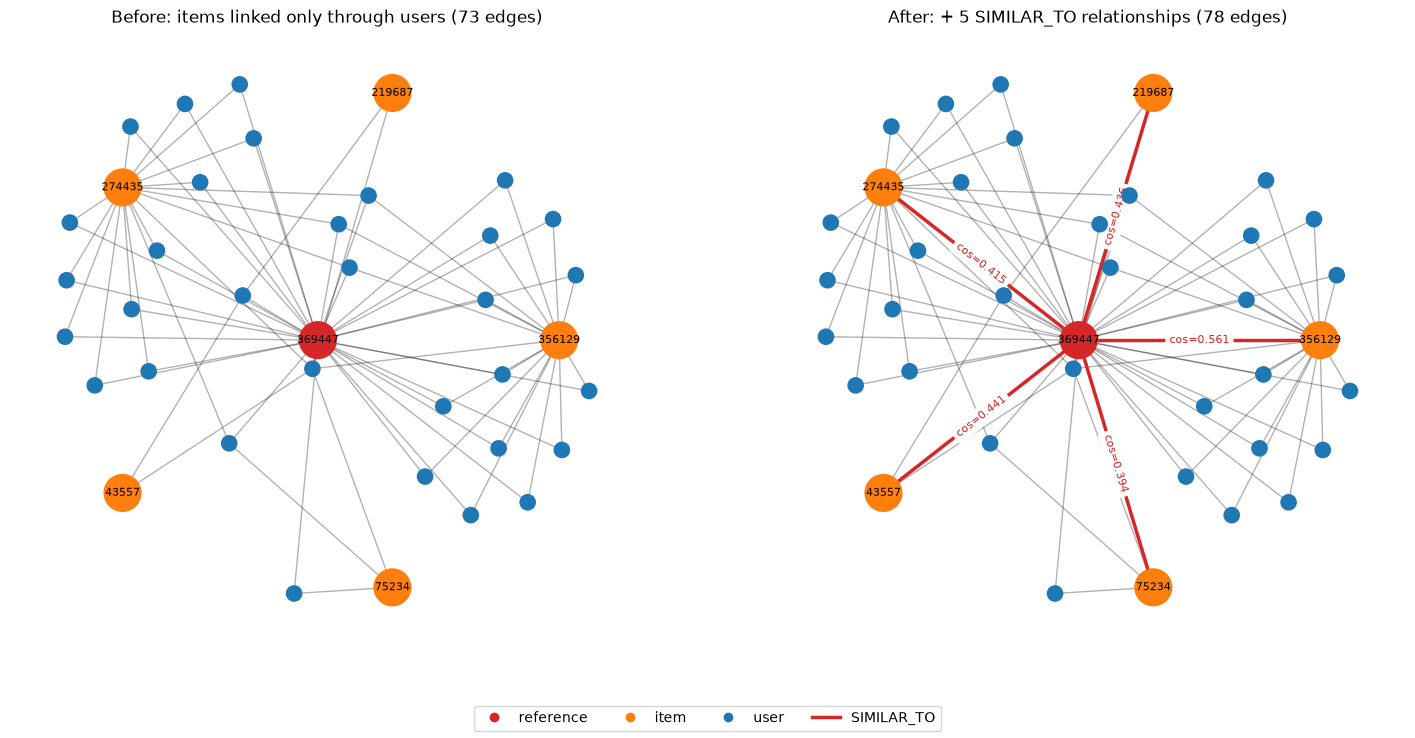

In [33]:
G_before = nx.Graph()
for row in before.itertuples():
    ref, user, item = f"item {row.reference_item}", f"user {row.user}", f"item {row.similar_item}"
    G_before.add_node(ref, kind="reference")
    G_before.add_node(item, kind="item")
    G_before.add_node(user, kind="user")
    G_before.add_edge(user, ref, kind="interaction", label=row.rel_a)
    G_before.add_edge(user, item, kind="interaction", label=row.rel_b)

G_after = G_before.copy()
for row in after_similar.itertuples():
    G_after.add_edge(f"item {row.reference_item}", f"item {row.similar_item}", kind="similar",
                     label=f"cos={row.cosine:.3f}")

NODE_COLOR = {"reference": "tab:red", "item": "tab:orange", "user": "tab:blue"}
# reference item in the centre, similar items on a circle around it, users placed by the spring layout
ref_node = f"item {REF_ITEM}"
similar_nodes = [f"item {i}" for i in after_similar["similar_item"]]
fixed = {ref_node: (0.0, 0.0)}
for k, node in enumerate(similar_nodes):
    angle = 2 * np.pi * k / len(similar_nodes)
    fixed[node] = (np.cos(angle), np.sin(angle))
pos = nx.spring_layout(G_before, pos=fixed, fixed=list(fixed), seed=7, k=0.35)


def draw(G, ax, title):
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[NODE_COLOR[G.nodes[n]["kind"]] for n in G],
                           node_size=[700 if G.nodes[n]["kind"] != "user" else 120 for n in G])
    interaction = [e for e in G.edges if G.edges[e]["kind"] == "interaction"]
    similar = [e for e in G.edges if G.edges[e]["kind"] == "similar"]
    nx.draw_networkx_edges(G, pos, ax=ax, edgelist=interaction, alpha=0.3)
    nx.draw_networkx_edges(G, pos, ax=ax, edgelist=similar, edge_color="tab:red", width=2.5)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=8,
                            labels={n: n.split()[1] for n in G if G.nodes[n]["kind"] != "user"})
    nx.draw_networkx_edge_labels(G, pos, ax=ax, font_size=8, font_color="tab:red",
                                 edge_labels={e: G.edges[e]["label"] for e in similar})
    ax.set_title(title)
    ax.axis("off")


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))
draw(G_before, ax1, f"Before: items linked only through users ({G_before.number_of_edges()} edges)")
draw(G_after, ax2, f"After: + {len(after_similar)} SIMILAR_TO relationships ({G_after.number_of_edges()} edges)")
handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=k) for k, c in NODE_COLOR.items()]
handles.append(plt.Line2D([], [], color="tab:red", lw=2.5, label="SIMILAR_TO"))
fig.legend(handles=handles, loc="lower center", ncol=4)
plt.show()

In [34]:
composition_after = pd.DataFrame(run_query("""
    MATCH ()-[r]->()
    RETURN type(r) AS relationship_type, count(*) AS count
    ORDER BY count DESC
"""))
composition_after

,relationship_type,count
0,VIEWED,344995
1,IN_CATEGORY,77054
2,ADDED_TO_CART,9128
3,PURCHASED,2855
4,SIMILAR_TO,5


### Before vs after

| | Before | After |
|---|---|---|
| Relationship types in the database | VIEWED, ADDED_TO_CART, PURCHASED, IN_CATEGORY | + **SIMILAR_TO** (5 relationships) |
| How item 369447 relates to its similar items | Only indirectly, via 32 shared users (Item ← User → Item, 2 hops) | Directly (Item → Item, 1 hop) |
| Edges in the plotted subgraph | 73 | 78 |
| Where the similarity value lives | Nowhere; it has to be recomputed with the 4-step query from 7(a) | Stored as `s.cosine` / `s.shared_users` on the relationship |

- **Before**, finding the items most similar to 369447 means traversing every user of the item and every
  item of those users, then aggregating weights and norms (the long query in 7(a)).
- **After**, the same answer is a single 1-hop lookup:
  `MATCH (:Item {id: 369447})-[s:SIMILAR_TO]->(b) RETURN b.id, s.cosine ORDER BY s.cosine DESC`.
  The similarity has become part of the graph and can be used directly for recommendations or further
  graph queries.
- The plot shows the result clearly: 356129 and 274435 (17 shared users each) are strongly connected to
  the reference item through many users, while 43557, 219687 and 75234 are linked through only 2–3 users
  but still get a high cosine because those users weighted both items similarly. 4 of the 5 similar items
  are in the same category as the reference item (category 48), which supports the result.

# Part 2 – 1. KNN Recommendation for a Random User

## 1(a). Python script for the KNN recommendation

**Item-based KNN** is used, in line with the conclusion of question 6 (the item projection is more
informative and more stable than the user projection). For the target user `u`:

1. Take every item `i` the user interacted with in P1, with its VSM weight `w(u,i)`.
2. For each `i`, take its **k = 5 nearest neighbours** `j` in the item–item projection graph, ranked by
   cosine similarity (ties broken by the number of shared users).
3. Each neighbour gets the score $\text{score}(j) = \sum_i w(u,i) \cdot \cos(i,j)$. A neighbour of several
   items the user liked accumulates more evidence.
4. Items the user already interacted with in P1 are removed, and the top `N = 3` by score are advertised.

In [35]:
K_NEIGHBORS = 5   # k in KNN: nearest neighbours taken per item
N_RECOMMEND = 3   # number of items advertised


def nearest_items(item_idx, k=K_NEIGHBORS):
    """k nearest neighbours of an item in the projection graph, by cosine then shared users."""
    neighbours = sorted(G_item[item_idx].items(),
                        key=lambda kv: (kv[1]["cosine"], kv[1]["weight"]), reverse=True)
    return neighbours[:k]


def knn_recommend(user_id, k=K_NEIGHBORS, n=N_RECOMMEND):
    """Item-based KNN: score unseen neighbours of the user's P1 items by sum(weight * cosine)."""
    row = W.getrow(users.get_loc(user_id))
    seen = set(row.indices)
    scores, sources = {}, {}
    for i, w in zip(row.indices, row.data):
        for j, attr in nearest_items(i, k):
            if j in seen:
                continue
            scores[j] = scores.get(j, 0.0) + w * attr["cosine"]
            sources.setdefault(j, []).append(int(items[i]))
    ranked = sorted(scores.items(), key=lambda kv: kv[1], reverse=True)[:n]
    return pd.DataFrame(
        [(rank, int(items[j]), score, sources[j]) for rank, (j, score) in enumerate(ranked, 1)],
        columns=["rank", "item", "score", "because_user_saw"],
    )

### Random selection of the user (reproducible)

1. **Candidate pool**: users who interacted in **both** P1 (training) and P2 (testing), because a user who
   never comes back in P2 cannot be evaluated in question 2. Of those, only users for whom k = 5 KNN
   produces at least `N_RECOMMEND = 3` items are kept, since the question asks for 3 advertised items.
2. The candidate IDs are **sorted ascending**, so the list does not depend on the order Neo4j returns rows.
3. One user is drawn with `np.random.default_rng(SEED).choice(candidates)` with a fixed `SEED = 42`.
   The same seed on the same data always gives the same user.

In [36]:
SEED = 42

both_folds = [r["user"] for r in run_query("""
    MATCH (u:User)-[r:VIEWED|ADDED_TO_CART|PURCHASED]->(:Item)
    WITH u, collect(DISTINCT r.fold) AS folds
    WHERE 'P1' IN folds AND 'P2' IN folds
    RETURN u.id AS user
    ORDER BY user
""")]

candidates = np.array(sorted(u for u in both_folds if len(knn_recommend(u)) >= N_RECOMMEND))
rng = np.random.default_rng(SEED)
target_user = int(rng.choice(candidates))

print("Users in both P1 and P2              :", len(both_folds))
print(f"Candidates with >= {N_RECOMMEND} KNN recommendations :", len(candidates))
print("Selected user (seed 42)              :", target_user)

Users in both P1 and P2              : 1066
Candidates with >= 3 KNN recommendations : 578
Selected user (seed 42)              : 111980


In [37]:
history = pd.DataFrame(run_query("""
    MATCH (u:User {id: $user})-[r]->(i:Item)
    WHERE r.fold = 'P1'
    RETURN i.id AS item, collect(type(r)) AS interactions
    ORDER BY item
""", user=target_user))
history["weight"] = [float(W[users.get_loc(target_user), items.get_loc(i)]) for i in history["item"]]
print(f"P1 history of user {target_user}:")
history

P1 history of user 111980:


,item,interactions,weight
0,464731,[VIEWED],1.0


The k = 5 nearest neighbours found for each item in the user's history (the "KNN determination" step):

In [38]:
row = W.getrow(users.get_loc(target_user))
knn_table = pd.DataFrame(
    [(int(items[i]), rank, int(items[j]), attr["cosine"], int(attr["weight"]), j in set(row.indices))
     for i in row.indices
     for rank, (j, attr) in enumerate(nearest_items(i), 1)],
    columns=["seen_item", "neighbour_rank", "neighbour_item", "cosine", "shared_users", "already_seen"],
)
knn_table

,seen_item,neighbour_rank,neighbour_item,cosine,shared_users,already_seen
0,464731,1,322164,0.810163,2,False
1,464731,2,331514,0.790638,2,False
2,464731,3,98425,0.784921,2,False
3,464731,4,464220,0.781069,2,False
4,464731,5,192876,0.773364,2,False


## 1(b). The 3 advertised items for k = 5

In [39]:
recommendations = knn_recommend(target_user)
recommendations

,rank,item,score,because_user_saw
0,1,322164,0.810163,[464731]
1,2,331514,0.790638,[464731]
2,3,98425,0.784921,[464731]


# Part 2 – 2. Evaluation: Hit@5 and NDCG@5

The ground truth is the set of items the user interacted with in the **testing fold P2**, taken from
Neo4j. Relevance is binary: an advertised item is relevant if the user interacted with it in P2.

- **Hit@K** = 1 if at least one of the top-K recommendations is relevant, otherwise 0.
- **NDCG@K** = DCG@K / IDCG@K, with
  $\text{DCG@K} = \sum_{r=1}^{K} \frac{rel_r}{\log_2(r + 1)}$. IDCG@K is the DCG of a perfect ranking,
  meaning all relevant items at the top, using $\min(|\text{relevant}|, K)$ positions.

Only 3 items are advertised, so with K = 5 the list is shorter than the cutoff: positions 4–5 are empty
and count as non-relevant.

In [40]:
K_EVAL = 5

test_items = pd.DataFrame(run_query("""
    MATCH (u:User {id: $user})-[r]->(i:Item)
    WHERE r.fold = 'P2'
    RETURN i.id AS item, collect(type(r)) AS interactions
    ORDER BY item
""", user=target_user))
relevant = set(test_items["item"])
print(f"P2 (ground truth) of user {target_user}: {len(relevant)} item(s)")
test_items

P2 (ground truth) of user 111980: 4 item(s)


,item,interactions
0,69758,[VIEWED]
1,140461,[VIEWED]
2,298721,[VIEWED]
3,450594,"[VIEWED, VIEWED]"


In [41]:
def hit_at_k(recommended, relevant, k):
    return int(any(item in relevant for item in recommended[:k]))


def ndcg_at_k(recommended, relevant, k):
    dcg = sum(1 / np.log2(rank + 1) for rank, item in enumerate(recommended[:k], 1) if item in relevant)
    idcg = sum(1 / np.log2(rank + 1) for rank in range(1, min(len(relevant), k) + 1))
    return dcg / idcg if idcg > 0 else 0.0


recommended = recommendations["item"].tolist()

detail = recommendations[["rank", "item"]].copy()
detail["relevant"] = detail["item"].isin(relevant).astype(int)
detail["discount 1/log2(rank+1)"] = 1 / np.log2(detail["rank"] + 1)
detail["gain"] = detail["relevant"] * detail["discount 1/log2(rank+1)"]
display(detail)

dcg = detail["gain"].sum()
idcg = sum(1 / np.log2(r + 1) for r in range(1, min(len(relevant), K_EVAL) + 1))
print(f"DCG@{K_EVAL}  = {dcg:.4f}")
print(f"IDCG@{K_EVAL} = {idcg:.4f}  (ideal: {min(len(relevant), K_EVAL)} relevant item(s) at the top)")
print()
print(f"(a) Hit@{K_EVAL}  = {hit_at_k(recommended, relevant, K_EVAL)}")
print(f"(b) NDCG@{K_EVAL} = {ndcg_at_k(recommended, relevant, K_EVAL):.4f}")

,rank,item,relevant,discount 1/log2(rank+1),gain
0,1,322164,0,1.00000,0.0
1,2,331514,0,0.63093,0.0
2,3,98425,0,0.50000,0.0


DCG@5  = 0.0000
IDCG@5 = 2.5616  (ideal: 4 relevant item(s) at the top)

(a) Hit@5  = 0
(b) NDCG@5 = 0.0000


### Context: the same metrics over all candidate users

A single user is a very small sample, so the same pipeline is also run for every candidate user to see
how representative the result above is.

In [42]:
rows = []
for u in candidates:
    recs = knn_recommend(int(u))["item"].tolist()
    rel = {r["item"] for r in run_query(
        "MATCH (:User {id: $user})-[r]->(i:Item) WHERE r.fold = 'P2' RETURN DISTINCT i.id AS item", user=int(u))}
    rows.append((int(u), len(recs), len(rel), hit_at_k(recs, rel, K_EVAL), ndcg_at_k(recs, rel, K_EVAL)))

all_users = pd.DataFrame(rows, columns=["user", "n_recommended", "n_relevant", f"hit@{K_EVAL}", f"ndcg@{K_EVAL}"])
print(f"Users evaluated: {len(all_users)}")
all_users[[f"hit@{K_EVAL}", f"ndcg@{K_EVAL}"]].mean().to_frame("mean over all candidates")

Users evaluated: 578


,mean over all candidates
hit@5,0.012111
ndcg@5,0.008606


### Analysis

**Selected user and recommendation (1b)**: with seed 42 the user drawn is **111980** (out of 578
candidates). In P1 this user viewed only one item, **464731** (category 1219). Its k = 5 nearest neighbours
all share 2 users with it and have cosine 0.77–0.81, and the top 3 are advertised:

| Rank | Advertised item | Score (= cosine × weight 1) |
|---|---|---|
| 1 | 322164 | 0.810 |
| 2 | 331514 | 0.791 |
| 3 | 98425 | 0.785 |

**Evaluation (2)**: in P2 the user viewed 4 different items (69758, 140461, 298721, 450594), none of
which was advertised, so:

- **(a) Hit@5 = 0**: none of the advertised items appears in the user's P2 interactions.
- **(b) NDCG@5 = 0**: DCG@5 = 0 because there is no relevant item at any rank, while IDCG@5 = 2.5616 (4
  relevant items, so the ideal ranking has hits at ranks 1–4: 1 + 0.631 + 0.5 + 0.431).

**Why the result is 0, and how representative it is:**
- The user's interest changed between the folds. The P1 item is in category 1219, while the P2 items are
  in categories 47 and 274 (both under parent category 381). The advertised items are in yet other
  categories (619, 473, 491). One viewed item two months earlier is very weak evidence of what the user
  will look at next.
- The recommendation rests on only 2 shared users per neighbour, so the high cosine values (≈0.8) come
  from very little evidence. This is the sparsity problem described in questions 4–5.
- Over all 578 candidate users, the same pipeline gives a mean **Hit@5 ≈ 0.012** and **NDCG@5 ≈ 0.009**,
  so a miss is the typical outcome on this dataset, not bad luck with the random draw.
- KNN removes items the user already saw in P1, but 158 of the 1,066 returning users (≈15%) interact
  again in P2 with an item they saw in P1. Allowing previously seen items, or mixing in popular items in
  the user's current categories, are natural ways to improve these numbers.